# GEM-FISH — joint Hi-C + FISH 3-D reconstruction

:func:`uchrom.recon.fish.reconstruct_gem_fish` is an independent
PyTorch reimplementation of Abbas et al. 2019 (*Nature Communications*,
doi:10.1038/s41467-019-10005-6).  It solves a three-stage optimisation
that fuses bulk Hi-C contacts with FISH-measured pairwise distances
into a single 3-D chromosome model.

Pipeline (per chromosome):

1. **TAD partition** — call the Dixon directionality-index caller on
   the Hi-C matrix.
2. **Stage 1 — TAD-level** gradient descent on ``C_g = C_1 + λ_E·C_2
   + λ_F·C_3`` (Hi-C KL + polymer prior + FISH inter-TAD distance).
3. **Stage 2 — intra-TAD** per-TAD descent on ``C_t = C_1 + λ_E·C_2 +
   λ_R·C_4`` (intra-TAD Hi-C KL + polymer prior + FISH Rg target).
4. **Stage 3 — assembly** — Kabsch-style rotation of each intra-TAD
   cloud around its Stage-1 centre.

The notebook has two parts.  The first runs end-to-end on a **fully
synthetic** chain so you can see the pipeline's mechanics with a known
ground truth.  The second downloads Bintu et al. 2018 (*Science*, the
follow-up to the paper's original Wang 2016 FISH) per-trace imaging
data for IMR90 chr21:18.6-20.6 Mb, synthesises a matching Hi-C from
the population-mean distances, and runs GEM-FISH on it.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

from uchrom.recon.fish._tad_level import (
    Stage1Params, reconstruct_tad_level,
)
from uchrom.recon.fish._intra_tad import (
    Stage2Params, reconstruct_intra_tad,
)
from uchrom.recon.fish._assembly import assemble
from uchrom.recon.fish._hic import contact_to_distance


## Part 1 — Synthetic end-to-end

Generate a known polymer chain organised into 5 tight TADs, fabricate
Hi-C contacts from ``f = 1/(1+d)`` and FISH distances from the truth
with noise, then run each of the three stages and compare to the
ground truth at every step.


In [2]:
rng = np.random.default_rng(0)
n_tads, bins_per_tad = 5, 20
truth = []
centre = np.zeros(3)
for t in range(n_tads):
    walk = np.cumsum(rng.normal(0, 0.3, (bins_per_tad, 3)), axis=0)
    truth.append(walk - walk.mean(0) + centre)
    centre = centre + 5.0 * (np.array([1.,0,0]) + 0.3 * rng.normal(0, 1, 3))
truth = np.vstack(truth)
N = truth.shape[0]
tad_bins = [(t*bins_per_tad, (t+1)*bins_per_tad) for t in range(n_tads)]
tad_centres_true = np.array([truth[s:e].mean(0) for (s, e) in tad_bins])

D_true = cdist(truth, truth)
contacts = 1.0 / (1.0 + D_true); np.fill_diagonal(contacts, 0)

# Inter-TAD contacts
inter_contacts = np.zeros((n_tads, n_tads))
for i, (si, ei) in enumerate(tad_bins):
    for j, (sj, ej) in enumerate(tad_bins):
        inter_contacts[i, j] = contacts[si:ei, sj:ej].sum()

# FISH centre distances + noise
F = cdist(tad_centres_true, tad_centres_true)
F = F + rng.normal(0, 0.1, F.shape); np.fill_diagonal(F, 0)

# Rg² targets per TAD (with noise)
rg_targets = []
for (s, e) in tad_bins:
    sub = truth[s:e]
    rg2 = ((sub - sub.mean(0)) ** 2).sum(1).mean()
    rg_targets.append(rg2 * (1 + 0.05 * rng.standard_normal()))

print(f'Ground truth: {N} bins across {n_tads} TADs')


Ground truth: 100 bins across 5 TADs


In [3]:
# Stage 1 — TAD-level
tad_centres_recon, s1_info = reconstruct_tad_level(
    inter_contacts, F,
    params=Stage1Params(
        lambda_E=0.05, lambda_F=0.5,
        n_iter=500, n_ensemble=20, device='cpu',
    ),
)
iu = np.triu_indices(n_tads, 1)
corr_s1 = np.corrcoef(cdist(tad_centres_recon, tad_centres_recon)[iu],
                      cdist(tad_centres_true, tad_centres_true)[iu])[0, 1]
print(f'Stage 1 centre-distance correlation: {corr_s1:.3f}')


Stage 1 centre-distance correlation: 1.000


In [4]:
# Stage 2 — intra-TAD
intra_coords, s2_info = reconstruct_intra_tad(
    contacts, tad_bins,
    target_rg_sq_per_tad=rg_targets,
    params=Stage2Params(
        lambda_E=0.05, lambda_R=0.01,
        n_iter=300, n_ensemble=6, device='cpu',
    ),
)
per_tad_corr = []
for i, (s, e) in enumerate(tad_bins):
    Di = cdist(intra_coords[i], intra_coords[i])
    Dt = cdist(truth[s:e], truth[s:e])
    n = e - s
    ci = np.corrcoef(Di[np.triu_indices(n, 1)],
                     Dt[np.triu_indices(n, 1)])[0, 1]
    per_tad_corr.append(ci)
print(f'Stage 2 mean intra-TAD distance corr: {np.mean(per_tad_corr):.3f}')


Stage 2 mean intra-TAD distance corr: 0.925


In [5]:
# Stage 3 — assembly
tad_mid = np.array([(s + e - 1) / 2 * bins_per_tad for (s, e) in tad_bins])
genomic = np.abs(tad_mid[:, None] - tad_mid[None, :]).astype(np.float64)
gap = contact_to_distance(
    inter_contacts, genomic_distances=genomic,
    alpha=0.25, fallback_c=1.0, fallback_beta=0.5,
)
final = assemble(tad_centres_recon, intra_coords, inter_tad_distances=gap)

corr_final = np.corrcoef(cdist(final, final)[np.triu_indices(N, 1)],
                         D_true[np.triu_indices(N, 1)])[0, 1]
print(f'Final chain distance correlation: {corr_final:.3f}')


Final chain distance correlation: 0.901


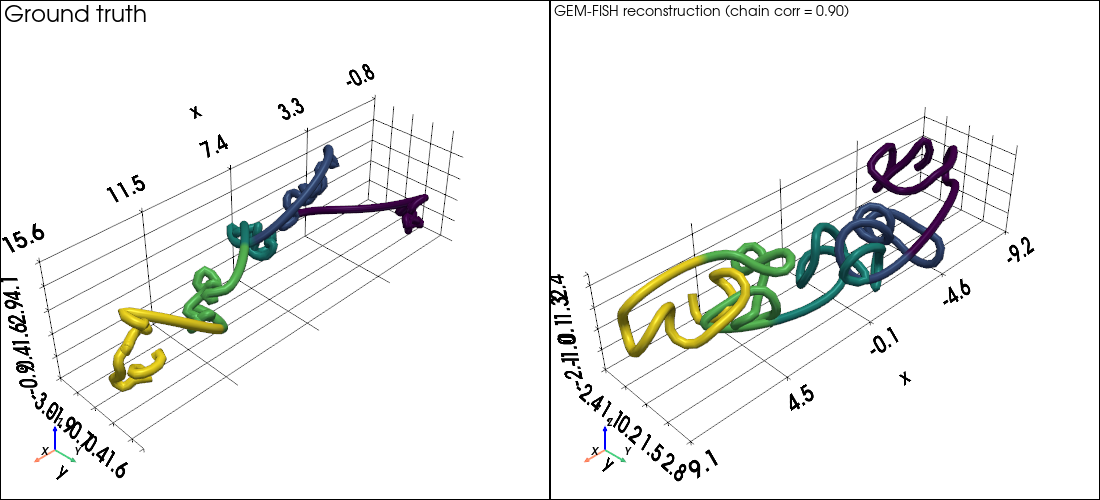

In [6]:
# Visualise truth vs reconstruction using uchrom.pl.plot_structure_3d.
# Use PyVista subplot so both tubes render side-by-side in one figure.
import pyvista as pv
from uchrom.pl import plot_structure_3d

# TAD-membership scalar so each TAD is coloured distinctly
tad_scalar = np.concatenate([
    np.full(e - s, t, dtype=np.float64) for t, (s, e) in enumerate(tad_bins)
])

plotter = pv.Plotter(shape=(1, 2), notebook=True, window_size=(1100, 500))

plotter.subplot(0, 0)
plotter.add_text('Ground truth', font_size=10)
plot_structure_3d(
    truth, colour=tad_scalar, cmap='viridis',
    plotter=plotter, show=False,
)

plotter.subplot(0, 1)
plotter.add_text(
    f'GEM-FISH reconstruction (chain corr = {corr_final:.2f})', font_size=10,
)
plot_structure_3d(
    final, colour=tad_scalar, cmap='viridis',
    plotter=plotter, show=False,
)

plotter.show(jupyter_backend='static')


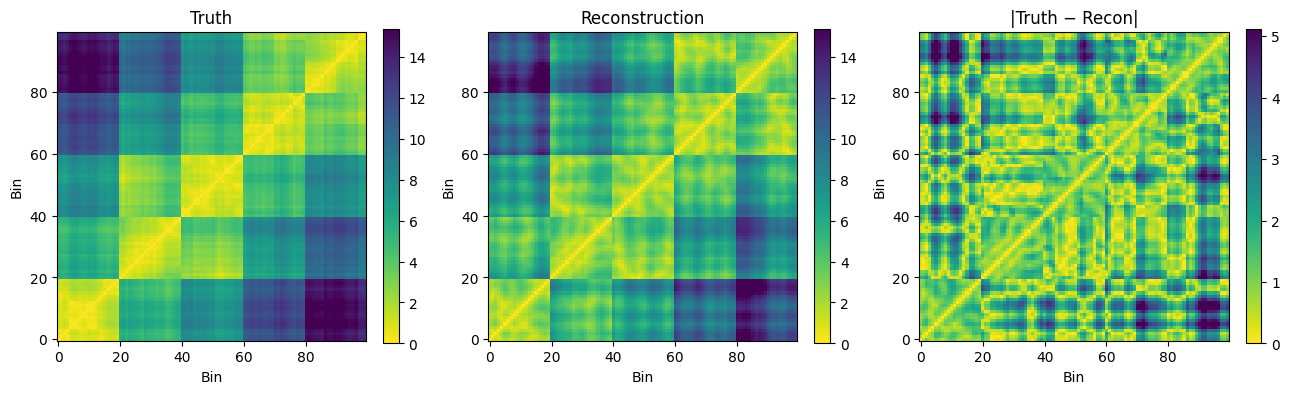

In [7]:
# Distance-matrix comparison
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
vmax = np.percentile(D_true, 98)
for ax, mat, title in zip(
    axes,
    [D_true, cdist(final, final), np.abs(D_true - cdist(final, final))],
    ['Truth', 'Reconstruction', '|Truth − Recon|'],
):
    im = ax.imshow(mat, cmap='viridis_r', origin='lower',
                   vmax=vmax if title != '|Truth − Recon|' else vmax/3)
    ax.set_title(title); ax.set_xlabel('Bin'); ax.set_ylabel('Bin')
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()


## Part 2 — Paper-faithful IMR90 chr21 reconstruction

Load the real Bintu 2018 FISH data (auto-downloaded) and the real
Rao 2014 IMR90 Hi-C (small 30-kb `.cool` shipped under `example-data/`,
derived from 4DN accession [4DNFI4QQPDMR](https://data.4dnucleome.org/4DNFI4QQPDMR/)),
then run the **one-shot** `reconstruct_gem_fish` entry point.


In [8]:
from pathlib import Path
import urllib.request
from uchrom.io import read_bintu_tracing

DATA_URL = (
    'https://raw.githubusercontent.com/BogdanBintu/ChromatinImaging/'
    'master/Data/IMR90_chr21-18-20Mb.csv'
)

def _repo_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'pyproject.toml').exists():
            return p
    return Path.cwd()

# Auto-download Bintu 2018 (~2 MB) if absent
root = _repo_root()
bintu_csv = root / 'example-data' / 'IMR90_chr21-18-20Mb.csv'
if not bintu_csv.exists():
    print(f'[data] downloading Bintu 2018 (~2 MB) → {bintu_csv}')
    urllib.request.urlretrieve(DATA_URL, bintu_csv)

# Load into ChromData via the Bintu reader
fish_cd = read_bintu_tracing(
    str(bintu_csv), chrom='chr21',
    start_bp=18_627_714,    # hg38, from the Bintu repo README
    resolution_bp=30_000,
)
print(fish_cd)
print(f'  n_traces: {fish_cd.traces.shape[0] if fish_cd.traces is not None else fish_cd.spots["trace_id"].nunique()}')

# Hi-C .cool is shipped in the repo (0.3 MB, chr21 only, 30 kb)
hic_cool = root / 'example-data' / 'IMR90_chr21_30kb.cool'
print(f'Hi-C: {hic_cool} ({hic_cool.stat().st_size / 1e6:.2f} MB)')


ChromData: n_spots=77797, n_traces=1277, n_cells=1277
  spots:   ['chrom', 'start', 'end', 'trace_id', 'cell_id']
  uns:     ['xyz_unit', 'genome_assembly', 'source']
  n_traces: 0
Hi-C: /Users/weizexu/Projects/U-Chrom/example-data/IMR90_chr21_30kb.cool (0.28 MB)


In [9]:
from uchrom.recon.fish import reconstruct_gem_fish, GEMFISHParams

cd, intermediate = reconstruct_gem_fish(
    hic_path=str(hic_cool),
    chrom='chr21',
    resolution=None,             # single-res .cool
    fish_cd=fish_cd,
    params=GEMFISHParams(
        lambda_E_tad=0.5, lambda_F=0.5,
        lambda_E_intra=0.05, lambda_R=0.01,
        stage1_iter=500, stage1_ensemble=20,
        stage2_iter=300, stage2_ensemble=6,
        tad_di_window=50, tad_di_min_size_frac=0.01,
        tad_max_size_frac=0.05,     # cap huge DI-called TADs (p-arm)
        device='auto', verbose=False,
    ),
    return_intermediate=True,
)
print(f'Reconstructed: {cd}')
print(f'  n_tads called: {cd.uns["gem_fish"]["n_tads"]}')
print(f'  final Stage-1 loss: {cd.uns["gem_fish"]["stage1_final_loss"]:.2f}')


Reconstructed: ChromData: n_spots=1557, n_traces=1
  spots:   ['chrom', 'start', 'end', 'trace_id']
  uns:     ['gem_fish', 'xyz_unit', 'genome_assembly']
  n_tads called: 24
  final Stage-1 loss: 1046669.88


In [10]:
# Evaluate: how well does the reconstruction match the FISH
# population-mean pairwise-distance matrix?
from uchrom.fea.distance import _bin_coord_cube, _pairwise_distance_per_trace

df_fish = fish_cd.to_dataframe()
cube, fish_bin_ids, _ = _bin_coord_cube(df_fish, chrom='chr21')
D_fish = np.nanmedian(_pairwise_distance_per_trace(cube), axis=0)

# Map each FISH bin to its corresponding Hi-C bin
bin_starts = cd.spots['start'].to_numpy()
fish_starts = np.array([s for s, _ in fish_bin_ids])
idx = np.array([int(np.argmin(np.abs(bin_starts - fs))) for fs in fish_starts])
D_recon = cdist(cd.coords[idx], cd.coords[idx])

iu_r = np.triu_indices(D_fish.shape[0], 1)
finite = np.isfinite(D_fish[iu_r]) & np.isfinite(D_recon[iu_r])
corr_real = np.corrcoef(D_fish[iu_r][finite], D_recon[iu_r][finite])[0, 1]
print(f'Reconstruction vs FISH pop-mean correlation: {corr_real:.3f}')
print(f'  evaluated over {finite.sum()} bin pairs in the Bintu imaged region')


Reconstruction vs FISH pop-mean correlation: 0.649
  evaluated over 2080 bin pairs in the Bintu imaged region


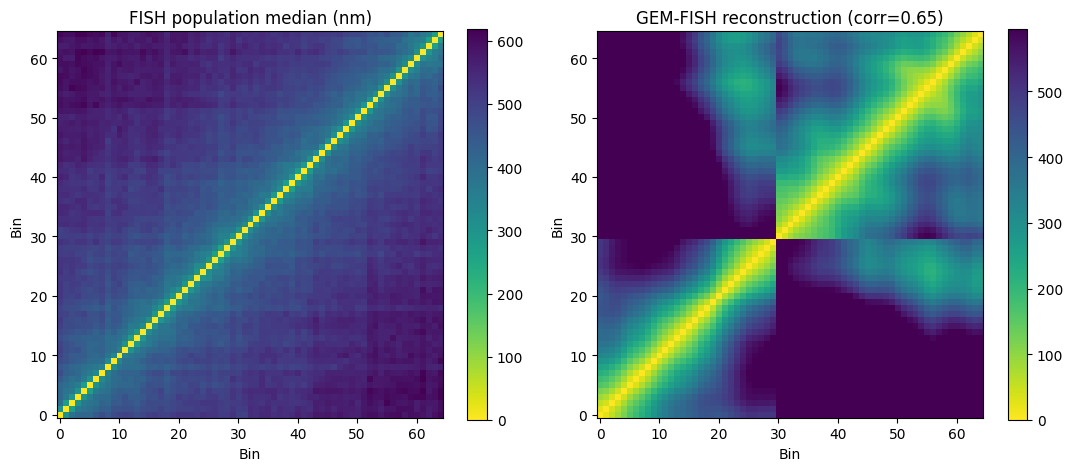

In [11]:
# Visualise.  Scale the recon distance matrix back to nm via the mean
# ratio with FISH so the two heat-maps are directly comparable.
scale_est = np.nanmean(D_fish[iu_r][finite]) / np.mean(D_recon[iu_r][finite])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

im0 = axes[0].imshow(D_fish, cmap='viridis_r', origin='lower')
axes[0].set_title('FISH population median (nm)')
plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(D_recon * scale_est, cmap='viridis_r', origin='lower',
                      vmax=np.nanpercentile(D_fish, 98))
axes[1].set_title(f'GEM-FISH reconstruction (corr={corr_real:.2f})')
plt.colorbar(im1, ax=axes[1])

for ax in axes:
    ax.set_xlabel('Bin'); ax.set_ylabel('Bin')
plt.tight_layout()
plt.show()


## 3-D rendering of the reconstructed chain

:func:`uchrom.pl.plot_structure_3d` is a PyVista-based renderer
(same stack the `uchrom.browser` uses, without the Qt window) that
draws the reconstructed chain as a smooth tube coloured along the
genomic direction.


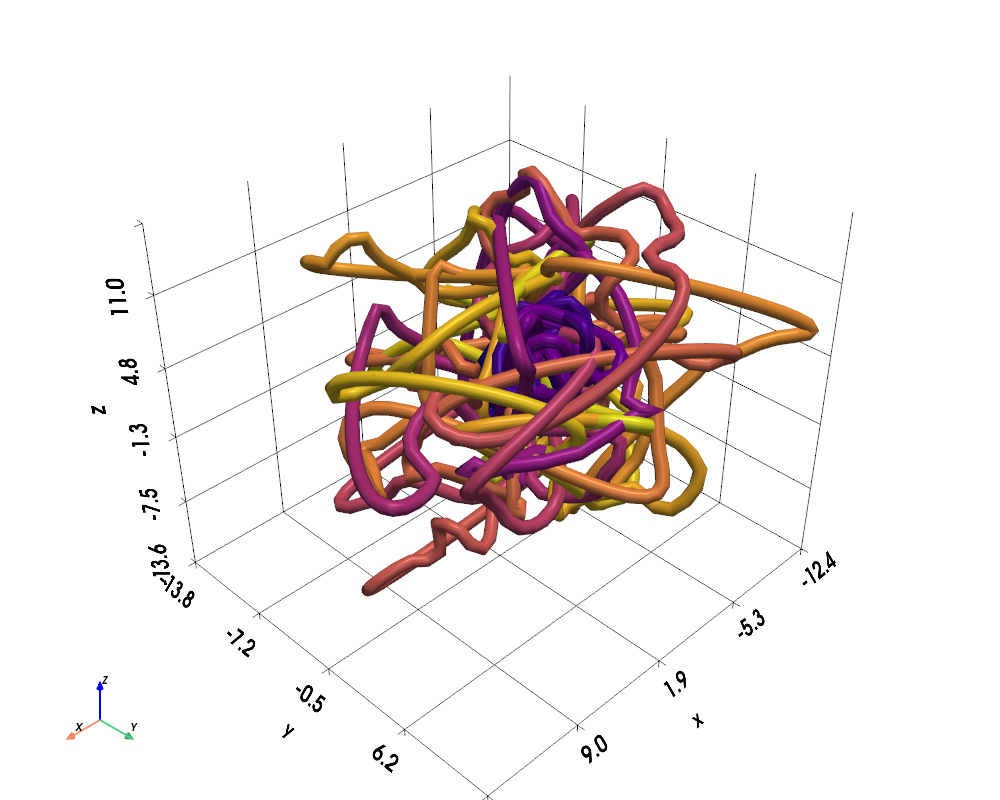

In [12]:
from uchrom.pl import plot_structure_3d

plot_structure_3d(
    cd, chrom='chr21',
    colour='bin', cmap='plasma',
    window_size=(1000, 800),
    notebook=True, jupyter_backend='static',
)


## Scaling up to other chromosomes

`IMR90_chr21_30kb.cool` only contains chr21.  For other chromosomes
(or a different resolution) download the full Rao 2014 IMR90 `.mcool`
from 4DN (~810 MB, public S3):

```
https://4dn-open-data-public.s3.amazonaws.com/fourfront-webprod/wfoutput/
1c856462-1e76-4850-bfa6-defcf1524d42/4DNFI4QQPDMR.mcool
```

Then:

```python
cd = reconstruct_gem_fish(
    hic_path='4DNFI4QQPDMR.mcool',
    chrom='chr20',
    resolution=30_000,         # required for .mcool
    fish_cd=fish_cd,           # swap in FISH for that chromosome
    params=GEMFISHParams(device='auto'),
)
cd.write('imr90_chr20_gemfish.h5cd')
```


## Notes and caveats

- **λ weights** in the paper (λ_E = 5 × 10¹², λ_F = 1 × 10⁻⁸) are
  calibrated for raw Hi-C counts without row-normalisation.  The
  PyTorch ``C_1`` here row-normalises inside the loss, so the effective
  weights differ — our defaults (λ_E = 0.05, λ_F = 0.01) balance the
  three terms for unit-scale inputs.
- **Single model vs ensemble**: ``reconstruct_tad_level`` returns the
  single best model from an ``n_ensemble`` batch by default.  Pass
  ``return_all=True`` to get all ensemble members for downstream
  clustering / averaging.
- **Assembly** here uses a single-anchor Kabsch per TAD, which is
  a simplification of the paper's gradient-descent assembly.  Good
  enough for the tutorial; for production use you may want to augment
  the initial rotation with a short local refinement step.
- **FISH coverage**: the Bintu 2018 CSV only covers
  chr21:18.6–20.6 Mb (65 bins out of the 1 557-bin chromosome).  The
  FISH C_3 / C_4 terms influence only the TADs that fall inside that
  region; the rest of the chromosome is shaped by Hi-C alone, which
  is the expected behaviour when FISH coverage is partial.
